## Topic 12-Machine Learning - Ensemble Methods

**Question 1**

Using the Breast Cancer (load_breast_cancer()) dataset, train a Random Forest Classifier and evaluate its performance using Accuracy, Precision, Recall, and F1-Score.

In [1]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))

print(classification_report(y_test, y_pred, target_names=data.target_names))

Accuracy: 0.956140350877193
Precision: 0.958904109589041
Recall: 0.9722222222222222
F1-Score: 0.9655172413793104
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



**Question 2**

Using the Wine (load_wine()) dataset, implement an AdaBoost Classifier and compare its performance with a Decision Tree Classifier.

In [2]:
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, classification_report

data = load_wine()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

ada_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=50,
    random_state=42
)
ada_model.fit(X_train, y_train)
ada_pred = ada_model.predict(X_test)

results = pd.DataFrame({
    "Model": ["Decision Tree", "AdaBoost"],
    "Accuracy": [
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, ada_pred)
    ]
})

print(results.to_string(index=False))

print(classification_report(y_test, ada_pred, target_names=data.target_names))


        Model  Accuracy
Decision Tree  0.944444
     AdaBoost  0.916667
              precision    recall  f1-score   support

     class_0       0.86      1.00      0.92        12
     class_1       0.92      0.86      0.89        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.92        36
   macro avg       0.93      0.92      0.92        36
weighted avg       0.92      0.92      0.92        36



**Question 3**

Using the Diabetes (load_diabetes()) dataset, build a Random Forest Regressor and evaluate the model using MAE, MSE, RMSE, and R² Score.

In [3]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

data = load_diabetes()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mse)
print("RMSE:", np.sqrt(mse))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 44.053033707865175
MSE: 2952.0105887640448
RMSE: 54.332408273184846
R2 Score: 0.4428225673999313


**Question 4**

Using the California Housing (fetch_california_housing()) dataset, train a Gradient Boosting Regressor and analyze the feature importance.

MSE: 0.2939973248643864
R2 Score: 0.7756446042829697
MedInc        0.604264
AveOccup      0.122835
Longitude     0.109853
Latitude      0.098533
HouseAge      0.034118
AveRooms      0.023948
AveBedrms     0.005100
Population    0.001348
dtype: float64


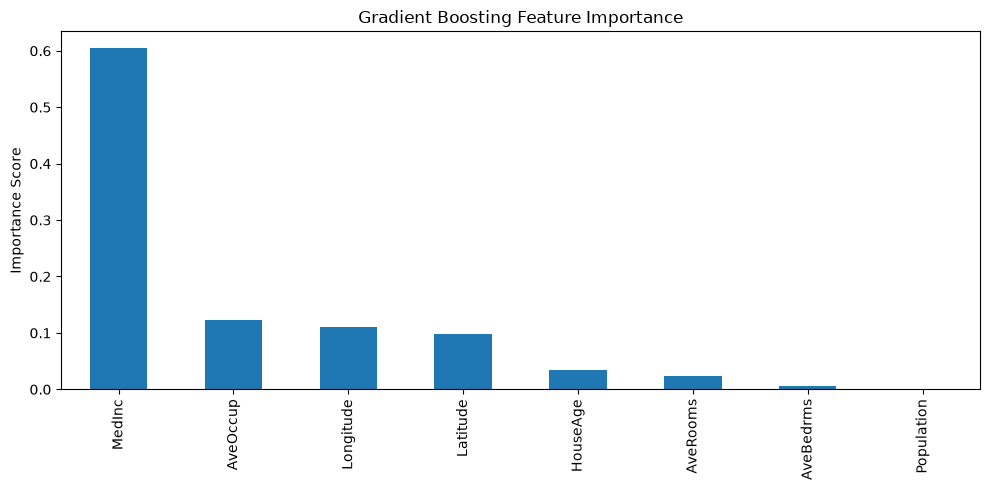

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

data = fetch_california_housing()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
model = GradientBoostingRegressor(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("MSE:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
    ).sort_values(ascending=False)

print(importance)

importance.plot(kind="bar", figsize=(10, 5))
plt.title("Gradient Boosting Feature Importance")
plt.ylabel("Importance Score")
plt.tight_layout()
plt.show()

**Question 5**

Using the Breast Cancer (load_breast_cancer()) dataset, implement an Extra Trees Classifier and compare its performance with a Random Forest Classifier.

In [5]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

models = {
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=42)
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-Score": f1_score(y_test, pred)
    })

print(pd.DataFrame(results).to_string(index=False))

        Model  Accuracy  Precision   Recall  F1-Score
Random Forest   0.95614   0.958904 0.972222  0.965517
  Extra Trees   0.95614   0.958904 0.972222  0.965517


**Question 6**

Using the Iris (load_iris()) dataset, implement a Voting Classifier using Logistic Regression, Decision Tree, and K-Nearest Neighbors (KNN). Compare the performance of each individual model with the Voting Classifier.

In [6]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import accuracy_score

data = load_iris()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
dt = DecisionTreeClassifier(random_state=42)
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))

voting = VotingClassifier(
    estimators=[
        ("lr", lr),
        ("dt", dt),
        ("knn", knn)
    ],
    voting="hard"
)

models = {
    "Logistic Regression": lr,
    "Decision Tree": dt,
    "KNN": knn,
    "Voting Classifier": voting
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred)
    })

print(pd.DataFrame(results).to_string(index=False))


              Model  Accuracy
Logistic Regression  0.933333
      Decision Tree  0.933333
                KNN  0.933333
  Voting Classifier  0.933333


**Question 7**

Using the Digits (load_digits()) dataset, implement a Bagging Classifier with a Decision Tree as the base estimator and evaluate its performance.

In [7]:
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import accuracy_score, classification_report

data = load_digits()
X = pd.DataFrame(data.data)
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=50,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9194444444444444

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.94      0.94        36
           1       0.89      0.94      0.92        36
           2       1.00      0.94      0.97        35
           3       0.85      0.95      0.90        37
           4       0.92      0.94      0.93        36
           5       0.97      0.97      0.97        37
           6       1.00      0.94      0.97        36
           7       0.92      0.97      0.95        36
           8       0.80      0.69      0.74        35
           9       0.89      0.89      0.89        36

    accuracy                           0.92       360
   macro avg       0.92      0.92      0.92       360
weighted avg       0.92      0.92      0.92       360



**Question 8**

Using the Wine (load_wine()) dataset, implement a Stacking Classifier using Logistic Regression, Support Vector Machine (SVM), and Decision Tree as base models, with Random Forest as the final estimator. Compare the results with the individual models.

In [8]:
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.metrics import accuracy_score

data = load_wine()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
svm = make_pipeline(StandardScaler(), SVC())
dt = DecisionTreeClassifier(random_state=42)

stacking = StackingClassifier(
    estimators=[
        ("lr", lr),
        ("svm", svm),
        ("dt", dt)
          ],
    final_estimator=RandomForestClassifier(n_estimators=100, random_state=42)
)

models = {
    "Logistic Regression": lr,
    "SVM": svm,
    "Decision Tree": dt,
    "Stacking Classifier": stacking
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred)
    })

print(pd.DataFrame(results).to_string(index=False))

              Model  Accuracy
Logistic Regression  0.972222
                SVM  0.972222
      Decision Tree  0.944444
Stacking Classifier  0.944444


**Question 9**

Using the California Housing (fetch_california_housing()) dataset, compare the performance of Random Forest Regressor, Gradient Boosting Regressor, and Extra Trees Regressor using the same train-test split.

In [9]:
import pandas as pd
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor
)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

data = fetch_california_housing()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

models = {
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "Extra Trees": ExtraTreesRegressor(n_estimators=100, random_state=42)
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    mse = mean_squared_error(y_test, pred)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2 Score": r2_score(y_test, pred)
    })

print(pd.DataFrame(results).to_string(index=False))

            Model      MAE      MSE     RMSE  R2 Score
    Random Forest 0.327731 0.256022 0.505986  0.804624
Gradient Boosting 0.371643 0.293997 0.542215  0.775645
      Extra Trees 0.326997 0.253904 0.503889  0.806241


**Question 10**

Choose any two built-in datasets from Iris, Wine, Breast Cancer, Digits, Diabetes, or California Housing. Apply at least three different Ensemble Methods and prepare a comparative analysis based on model performance, execution time, and feature importance (where applicable).

In [10]:
import time
import numpy as np
import pandas as pd

from sklearn.datasets import load_breast_cancer, load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

results = []
cancer = load_breast_cancer()
Xc = pd.DataFrame(cancer.data, columns=cancer.feature_names)
yc = cancer.target
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.20, random_state=42, stratify=yc
)

classification_models = {
    "Random Forest": RandomForestClassifier(random_state=42),
    "Extra Trees": ExtraTreesClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42)
}

for name, model in classification_models.items():
    start = time.perf_counter()
    model.fit(Xc_train, yc_train)
    predictions = model.predict(Xc_test)
    elapsed = time.perf_counter() - start

    results.append({
        "Dataset": "Breast Cancer",
        "Model": name,
        "Metric": "Accuracy",
        "Score": accuracy_score(yc_test, predictions),
        "F1 Score": f1_score(yc_test, predictions),
        "Execution Time (s)": elapsed
    })
    diabetes = load_diabetes()
Xr = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
yr = diabetes.target

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    Xr, yr, test_size=0.20, random_state=42
)

regression_models = {
    "Random Forest": RandomForestRegressor(random_state=42),
    "Extra Trees": ExtraTreesRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

for name, model in regression_models.items():
    start = time.perf_counter()
    model.fit(Xr_train, yr_train)
    predictions = model.predict(Xr_test)
    elapsed = time.perf_counter() - start

    results.append({
        "Dataset": "Diabetes",
        "Model": name,
        "Metric": "R2 Score",
        "Score": r2_score(yr_test, predictions),
        "F1 Score": np.nan,
        "Execution Time (s)": elapsed
    })
    print(pd.DataFrame(results).to_string(index=False))

importance = pd.Series(
    regression_models["Random Forest"].feature_importances_,
    index=Xr.columns
).sort_values(ascending=False)

print(importance)

      Dataset         Model   Metric    Score  F1 Score  Execution Time (s)
Breast Cancer Random Forest Accuracy 0.956140  0.965517            0.656309
Breast Cancer   Extra Trees Accuracy 0.956140  0.965517            0.294481
Breast Cancer      AdaBoost Accuracy 0.956140  0.965986            0.661719
     Diabetes Random Forest R2 Score 0.442823       NaN            0.756096
      Dataset         Model   Metric    Score  F1 Score  Execution Time (s)
Breast Cancer Random Forest Accuracy 0.956140  0.965517            0.656309
Breast Cancer   Extra Trees Accuracy 0.956140  0.965517            0.294481
Breast Cancer      AdaBoost Accuracy 0.956140  0.965986            0.661719
     Diabetes Random Forest R2 Score 0.442823       NaN            0.756096
     Diabetes   Extra Trees R2 Score 0.468456       NaN            0.481565
      Dataset             Model   Metric    Score  F1 Score  Execution Time (s)
Breast Cancer     Random Forest Accuracy 0.956140  0.965517            0.656309
Brea